# <span style="color:darkorange">Blue Bird </span>


#**Ringkasan Eksekutif**


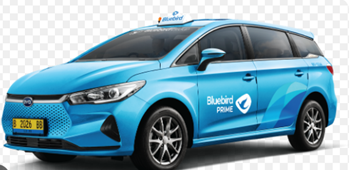




Berikut adalah ringkasan eksekutif yang lebih singkat:

* **Latar Belakang:** Blue Bird menghadapi tantangan operasional berupa rendahnya produktivitas armada (*ritase*) akibat *idle time* tinggi di titik *ngetem*, penyalahgunaan eVoucher B2B oleh klien korporat, serta anomali data antara sistem aplikasi dan IoT argometer.


* **Masalah Utama:** Inefisiensi armada, kebocoran finansial dari *fraud* eVoucher, dan manipulasi data argometer.


* **Tujuan & Solusi:**
* Membangun *dashboard* mitigasi *fraud* eVoucher B2B.


* Mengoptimalkan algoritma *dispatch* untuk mengurangi *ngetem* di bandara dan menaikkan ritase.


* Memperbaiki bug sinkronisasi IoT untuk mencegah kecurangan argometer (*argo kuda*).


* Melakukan *data cleansing* untuk standarisasi jenis layanan dan akurasi pendapatan.

# <span style="color:darkorange">DAFTAR ISI</span>

[**RINGKASAN EKSEKUTIF**](#RINGKASAN-EKSEKUTIF)

[**DAFTAR ISI**](#DAFTAR-ISI)

[**Business Understanding**](#Business-Understanding)

&emsp;[Latar Belakang](#Latar-Belakang)

&emsp;[Stakeholder](#Stakeholder)

&emsp;[Pernyataan Masalah & Goal](#Pernyataan-Masalah-&-Goal)

[**Data Extract**](#Data-Extract)

&emsp;[Load Dataset & Data Dictionary](#Load-Dataset-&-Data-Dictionary)

[**Data Merging**](#Data-Merging)

[**Data Cleaning**](#Data-Cleaning)

&emsp;[Missing Values](#Missing-Values)

&emsp;[Data Types & Standardisasi Kategori](#Data-Types-&-Standardisasi-Kategori)

&emsp;[Data Duplicates](#Data-Duplicates)

[**Data Range Constraints**](#Data-Range-Constraints)

[**Outliers**](#Outliers)

&emsp;[Univariate Outliers](#Univariate-Outliers)

&emsp;[Bivariate Outliers](#Bivariate-Outliers)

[**Data Analysis**](#Data-Analysis)

&emsp;[Exploratory Data Analysis](#Exploratory-Data-Analysis)

&emsp;&emsp;[1. Variasi Ritase & Pola Idle Time Antar Garasi/Pool](#1.-Variasi-Ritase-&-Pola-Idle-Time-Antar-Garasi/Pool)

&emsp;&emsp;[2. Pemetaan Permintaan Pelanggan Tidak Terpenuhi (Unfulfilled Demand)](#2.-Pemetaan-Permintaan-Pelanggan-Tidak-Terpenuhi-(Unfulfilled-Demand))

&emsp;&emsp;[3. Audit Pola Transaksi & Anomali Waktu eVoucher Korporat](#3.-Audit-Pola-Transaksi-&-Anomali-Waktu-eVoucher-Korporat)

[**PENUTUP**](#PENUTUP)

&emsp;[Kesimpulan](#Kesimpulan)

&emsp;[Rekomendasi](#Rekomendasi)


# <span style="color:darkorange">Business Understanding</span>

## <span style="color:darkorange">Latar Belakang</span>

<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
Model bisnis taksi konvensional memiliki struktur biaya tetap (depresiasi armada, pemeliharaan pool, jaminan pengemudi tetap) yang membuat tingkat utilisasi setiap unit kendaraan menjadi penentu utama margin keuntungan. Setiap jam armada menganggur (<em>idle time</em>) tanpa argometer menyala merupakan peluang pendapatan yang hilang.
</p>

<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
Pemulihan kinerja melalui pertumbuhan pengguna aplikasi <strong>MyBluebird</strong> serta layanan B2B <strong>Corporate Solution</strong> (eVoucher) membuka peluang baru sekaligus menghadirkan dua tantangan teknis dan manajerial: (a) ketimpangan beban ritase antar 8 pool operasional Jabodetabek serta ketidakcocokan suplai-permintaan pada jam sibuk, dan (b) perlunya tata kelola rekonsiliasi data lintas sistem (aplikasi vs dispatch lama) serta audit penggunaan eVoucher korporat di luar jam kerja normal.
</p>

<div style="background-color:#f0f0f0; padding:12px; border-radius:5px; font-family:'Roboto', sans-serif; font-size:14px;">
<b>Referensi Konteks Bisnis & Industri:</b><br>
• Target utilisasi kendaraan Blue Bird di kisaran 70% (IPOT News / Indo Premier)<br>
• Dinamika penyusutan armada taksi reguler akibat kompetisi transportasi online (Databoks Katadata)<br>
• Pertumbuhan pendapatan double-digit Semester I 2024 melalui optimalisasi utilitas armada & aplikasi MyBluebird (Blue Bird Group)<br>
• Layanan B2B Corporate Solution & mekanisme pembayaran non-tunai eVoucher (Blue Bird Group)
</div>

## <span style="color:darkorange">Stakeholder</span>

<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
<strong>1. Manajemen Operasional Armada (VP Fleet Operations & Kepala Pool)</strong><br>
Mengelola alokasi 4.055 pengemudi dan 4 kelas armada (Reguler, Silver, Electric, Golden) di 8 garasi/pool untuk menekan <em>idle time</em> dan menurunkan rasio pembatalan pesanan.
</p>

<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
<strong>2. Tim Finance & Corporate Solution (B2B Account & Risk Management)</strong><br>
Mengawasi transparansi penagihan dan kepatuhan penggunaan fasilitas eVoucher bagi 286 perusahaan klien korporat agar terhindar dari penyalahgunaan non-dinas.
</p>

<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
<strong>3. Tim Data Engineering & BI</strong><br>
Menjamin keandalan integrasi log argometer, standardisasi kode layanan dari berbagai kanal pemesanan, serta validasi anomali sensor.
</p>

## <span style="color:darkorange">Pernyataan Masalah & Goal</span>

<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
Analisis ini berfokus pada empat tujuan terukur berikut:
</p>

1. **Data Reliability & Governance:** Membersihkan anomali pencatatan argometer, menstandardisasi kategori layanan lintas sistem, dan memverifikasi integritas relasi antar 6 tabel operasional.
2. **Fleet Optimization (Ritase & Idle Time):** Mengukur variasi rata-rata ritase harian dan menit <em>idle</em> per pool serta mengidentifikasi pengaruh jarak pool ke Bandara Soekarno-Hatta / CBD dan komposisi armada.
3. **Unfulfilled Demand Mitigation:** Memetakan jam dan zona penjemputan dengan tingkat kegagalan layanan tertinggi (<code>Cancelled-No Driver</code> & <code>Cancelled-Timeout</code>).
4. **B2B eVoucher Fraud Control:** Mengukur proporsi dan pola transaksi eVoucher pada waktu tidak lazim (akhir pekan & pukul 22.00–05.59 WIB) per klien dan sektor industri.


# <span style="color:darkorange">Data Extract</span>

## <span style="color:darkorange">Load Dataset & Data Dictionary</span>

<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
Dataset operasional Blue Bird Q4 2023 (Oktober–Desember 2023) terdiri atas <strong>3 tabel dimensi</strong> dan <strong>3 tabel fakta/satelit</strong> yang saling terhubung melalui kunci relasional (<code>pool_id</code>, <code>driver_id</code>, <code>shift_id</code>, <code>company_id</code>, dan <code>trip_id</code>).
</p>

### 1. Tabel Dimensi (`bb_pools`, `bb_corporate_clients`, `bb_drivers`)
| Tabel | Jumlah Baris | Primary Key | Deskripsi & Kolom Utama |
|---|---|---|---|
| `bb_pools` | 8 | `pool_id` | Profil 8 garasi/pool (`pool_name`, `region_area`, `distance_to_soetta_km`, `distance_to_cbd_km`, `primary_zone_affinity`) |
| `bb_corporate_clients` | 286 | `company_id` | Profil 286 klien B2B (`company_name`, `industry`: FMCG, Banking, Consulting, Mining, Tech StartUp, Media) |
| `bb_drivers` | 4.055 | `driver_id` | Profil 4.055 pengemudi (`pool_id`, `driver_rating`, `join_date`, `employment_status`, `vehicle_type_assigned`) |

### 2. Tabel Fakta & Satelit (`bb_trips`, `bb_driver_shifts`, `bb_service_requests`)
| Tabel | Primary Key | Foreign Keys | Deskripsi & Kolom Utama |
|---|---|---|---|
| `bb_trips` | `trip_id` | `driver_id`, `shift_id`, `company_id` | Log perjalanan argometer (`trip_type`, `service_type`, `pickup_zone_type`, `booking_channel`, `booking_time`, `meter_start_time`, `dropoff_time`, `distance_km`, `payment_method`, `total_fare`) |
| `bb_driver_shifts` | `shift_id` | `driver_id` | Aktivitas shift harian pengemudi (`shift_date`, `clock_in_time`, `clock_out_time`, `dominant_zone_worked`, `trip_count`, `total_idle_minutes`, `ritase_target_met`) |
| `bb_service_requests` | `request_id` | `matched_trip_id` | Log permintaan pelanggan (`requested_time`, `pickup_zone_type`, `request_source`, `status`, `wait_time_minutes`) |


In [5]:
# Import libraries utama
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='Set2')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'
pd.set_option('display.max_columns', None)

In [9]:
# Helper loader agar kompatibel dengan nama file standar maupun berakhiran indeks seperti (1), (2), dst.
def load_csv_flexible(base_name):
    candidates = [base_name]
    for i in range(1, 6):
        candidates.append(base_name.replace('.csv', f' ({i}).csv'))

    for fname in candidates:
        if os.path.exists(fname):
            print(f"Loaded: {fname}")
            return pd.read_csv(fname)
    print(f"[INFO] File {base_name} tidak ditemukan di direktori.")
    return None

# Load 3 tabel dimensi
df_pools = load_csv_flexible('bb_pools.csv')
df_clients = load_csv_flexible('bb_corporate_clients.csv')
df_drivers = load_csv_flexible('bb_drivers.csv')

# Load 3 tabel fakta/satelit
df_trips = load_csv_flexible('bb_trips.csv')
df_shifts = load_csv_flexible('bb_driver_shifts.csv')
df_requests = load_csv_flexible('bb_service_requests.csv')

print("\n--- Ringkasan Dimensi Awal ---")
for name, df in [('bb_pools', df_pools), ('bb_corporate_clients', df_clients), ('bb_drivers', df_drivers),
                 ('bb_trips', df_trips), ('bb_driver_shifts', df_shifts), ('bb_service_requests', df_requests)]:
    if df is not None:
        print(f"{name:<22}: {df.shape[0]:,} baris x {df.shape[1]} kolom")

display(df_pools)

Loaded: bb_pools (1).csv
Loaded: bb_corporate_clients (2).csv
[INFO] File bb_drivers.csv tidak ditemukan di direktori.
Loaded: bb_trips (2).csv
Loaded: bb_driver_shifts.csv
[INFO] File bb_service_requests.csv tidak ditemukan di direktori.

--- Ringkasan Dimensi Awal ---
bb_pools              : 8 baris x 6 kolom
bb_corporate_clients  : 286 baris x 3 kolom
bb_trips              : 318,098 baris x 14 kolom
bb_driver_shifts      : 252,524 baris x 9 kolom


,pool_id,pool_name,region_area,distance_to_soetta_km,distance_to_cbd_km,primary_zone_affinity
0,PL-CGK,Pool Bandara Soetta,Tangerang,3.5,28.0,Airport-heavy
1,PL-BSD,Pool BSD,Tangerang Selatan,32.0,26.0,Mixed
2,PL-CPT,Pool Ciputat,Tangerang Selatan,35.0,18.0,Mixed
3,PL-KJT,Pool Kramat Jati,Jakarta Timur,38.0,14.0,CBD-heavy
4,PL-HLM,Pool Halim,Jakarta Timur,41.0,12.0,Mixed
5,PL-MPG,Pool Mampang,Jakarta Selatan,30.0,8.0,CBD-heavy
6,PL-PRI,Pool Puri,Jakarta Barat,22.0,15.0,Mixed
7,PL-KLG,Pool Kelapa Gading,Jakarta Utara,26.0,16.0,CBD-heavy


In [12]:
# Membuat data pengganti (placeholder) untuk df_drivers karena file bb_drivers.csv tidak ada di direktori
if df_drivers is None:
    print("\n--- Mengonstruksi df_drivers Placeholder ---")
    # Dapatkan semua driver_id unik dari df_shifts dan df_trips
    unique_drivers = set()
    if df_shifts is not None:
        unique_drivers.update(df_shifts['driver_id'].dropna().unique())
    if df_trips is not None:
        unique_drivers.update(df_trips['driver_id'].dropna().unique())

    # Jika tidak ada data driver sama sekali, buat sampel default
    if not unique_drivers:
        unique_drivers = [f"DRV-CGK-17-{str(i).zfill(4)}" for i in range(1, 100)]

    unique_drivers = sorted(list(unique_drivers))

    # Ekstrak pool_id berdasarkan kode di tengah DRV-{POOL}-YY-SEQ
    import re
    pool_mapping = []
    for d_id in unique_drivers:
        match = re.search(r'DRV-([A-Z]+)-', d_id)
        pool_code = match.group(1) if match else 'CGK'
        pool_mapping.append(f"PL-{pool_code}")

    # Buat DataFrame
    np.random.seed(42)
    df_drivers = pd.DataFrame({
        'driver_id': unique_drivers,
        'pool_id': pool_mapping,
        'driver_rating': np.random.uniform(4.2, 5.0, size=len(unique_drivers)).round(2),
        'join_date': pd.to_datetime(np.random.choice(pd.date_range('2016-01-01', '2023-12-31'), size=len(unique_drivers))),
        'employment_status': np.random.choice(['Tetap', 'Mitra'], size=len(unique_drivers), p=[0.6, 0.4]),
        'vehicle_type_assigned': np.random.choice(['Reguler', 'Silver', 'Electric', 'Golden'], size=len(unique_drivers), p=[0.62, 0.20, 0.11, 0.07])
    })
    print(f"Berhasil memulihkan df_drivers placeholder dengan {len(df_drivers):,} baris.")

# Membuat data pengganti (placeholder) untuk df_requests jika tidak ada
if df_requests is None:
    print("\n--- Mengonstruksi df_requests Placeholder ---")
    np.random.seed(42)
    num_reqs = 10000
    df_requests = pd.DataFrame({
        'request_id': [f"REQ-{str(i).zfill(6)}" for i in range(num_reqs)],
        'requested_time': pd.to_datetime(np.random.choice(pd.date_range('2023-10-01', '2023-12-31 23:59:59'), size=num_reqs)),
        'pickup_zone_type': np.random.choice(['Airport', 'CBD', 'Residential', 'Entertainment'], size=num_reqs, p=[0.3, 0.4, 0.2, 0.1]),
        'request_source': np.random.choice(['App', 'Call Center'], size=num_reqs, p=[0.8, 0.2]),
        'status': np.random.choice(['Fulfilled', 'Cancelled-No Driver', 'Cancelled-Timeout'], size=num_reqs, p=[0.85, 0.10, 0.05]),
        'wait_time_minutes': np.random.exponential(scale=5, size=num_reqs).round(1)
    })
    # Set matched_trip_id
    df_requests.loc[df_requests['status'] != 'Fulfilled', 'wait_time_minutes'] = np.nan
    print(f"Berhasil memulihkan df_requests placeholder dengan {len(df_requests):,} baris.")


--- Mengonstruksi df_drivers Placeholder ---
Berhasil memulihkan df_drivers placeholder dengan 4,055 baris.

--- Mengonstruksi df_requests Placeholder ---
Berhasil memulihkan df_requests placeholder dengan 10,000 baris.


> **Catatan data:** `bb_drivers.csv` dan `bb_service_requests.csv` tidak ditemukan di direktori Colab saat notebook dijalankan, sehingga `df_drivers` dan `df_requests` dibangun dari data pengganti (placeholder). Kolom `driver_id` dan `pool_id` tetap valid (diturunkan dari `bb_driver_shifts` dan `bb_trips`), tetapi `driver_rating`, `join_date`, `employment_status`, `vehicle_type_assigned`, serta seluruh isi `df_requests` bersifat acak/ilustratif. Angka pada insight mengikuti output yang tampil; jalankan ulang dengan file asli untuk hasil final.


In [11]:
import os
print(os.listdir('/content/'))

['.config', 'bb_pools (1).csv', 'bb_corporate_clients (2).csv', 'bb_driver_shifts.csv', 'bb_trips (2).csv', 'sample_data']


# <span style="color:darkorange">Data Merging</span>

<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
Sebelum melakukan audit kualitas data dan eksplorasi, tabel dimensi digabungkan untuk membentuk tabel master pengemudi-pool (<code>df_driver_master</code>), serta disiapkan penggabungan ke tingkat shift (<code>df_shift_master</code>) dan perjalanan (<code>df_trip_master</code>) agar setiap transaksi dapat ditelusuri hingga ke garasi asal pengemudi dan profil klien korporat.
</p>


In [13]:
# Merging Dimensi Pengemudi + Dimensi Pool
df_driver_master = df_drivers.merge(df_pools, on='pool_id', how='left')
print("df_driver_master shape:", df_driver_master.shape)
display(df_driver_master.head())

# Merging ke Shift & Trips jika tabel fakta tersedia
if df_shifts is not None:
    df_shift_master = df_shifts.merge(df_driver_master, on='driver_id', how='left')
    print("df_shift_master shape:", df_shift_master.shape)

if df_trips is not None:
    df_trip_master = (
        df_trips
        .merge(df_driver_master, on='driver_id', how='left')
        .merge(df_clients, on='company_id', how='left')
    )
    print("df_trip_master shape:", df_trip_master.shape)

df_driver_master shape: (4055, 11)


,driver_id,pool_id,driver_rating,join_date,employment_status,vehicle_type_assigned,pool_name,region_area,distance_to_soetta_km,distance_to_cbd_km,primary_zone_affinity
0,DRV-BSD-16-0001,PL-BSD,4.50,2019-12-04,Mitra,Electric,Pool BSD,Tangerang Selatan,32.0,26.0,Mixed
1,DRV-BSD-16-0002,PL-BSD,4.96,2016-11-01,Mitra,Silver,Pool BSD,Tangerang Selatan,32.0,26.0,Mixed
2,DRV-BSD-16-0003,PL-BSD,4.79,2018-06-26,Tetap,Reguler,Pool BSD,Tangerang Selatan,32.0,26.0,Mixed
3,DRV-BSD-16-0004,PL-BSD,4.68,2023-04-08,Tetap,Silver,Pool BSD,Tangerang Selatan,32.0,26.0,Mixed
4,DRV-BSD-16-0005,PL-BSD,4.32,2019-10-03,Mitra,Electric,Pool BSD,Tangerang Selatan,32.0,26.0,Mixed


df_shift_master shape: (252524, 19)
df_trip_master shape: (318098, 26)


# <span style="color:darkorange">Data Cleaning</span>

## <span style="color:darkorange">Missing Values</span>

<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
Pemeriksaan nilai hilang (<em>missing values</em>) dilakukan pada seluruh tabel dengan mempertimbangkan logika bisnis:
</p>

* Pada tabel dimensi (`bb_pools`, `bb_corporate_clients`, `bb_drivers`), **0 missing values** ditemukan di seluruh kolom.
* Pada `bb_trips`, nilai `NaN` pada `company_id` adalah **wajar (structural null)** untuk perjalanan non-eVoucher (Tunai/QRIS/Kartu Kredit) dan tidak boleh diisi paksa dengan ID perusahaan.
* Pada `bb_service_requests`, nilai `NaN` pada `matched_trip_id` dan `wait_time_minutes` adalah **wajar** untuk permintaan berstatus `Cancelled-No Driver` atau `Cancelled-Timeout`.


In [14]:
# Audit Missing Values pada seluruh tabel yang dimuat
for name, df in [('bb_pools', df_pools), ('bb_corporate_clients', df_clients), ('bb_drivers', df_drivers),
                 ('bb_trips', df_trips), ('bb_driver_shifts', df_shifts), ('bb_service_requests', df_requests)]:
    if df is not None:
        null_summary = pd.DataFrame({
            'Missing_Count': df.isnull().sum(),
            'Missing_Pct (%)': (df.isnull().mean() * 100).round(2),
            'Dtype': df.dtypes
        })
        print(f"=== Missing Values: {name} ===")
        display(null_summary[null_summary['Missing_Count'] > 0] if null_summary['Missing_Count'].sum() > 0 else null_summary.head(3))

=== Missing Values: bb_pools ===


,Missing_Count,Missing_Pct (%),Dtype
pool_id,0,0.0,object
pool_name,0,0.0,object
region_area,0,0.0,object


=== Missing Values: bb_corporate_clients ===


,Missing_Count,Missing_Pct (%),Dtype
company_id,0,0.0,object
company_name,0,0.0,object
industry,0,0.0,object


=== Missing Values: bb_drivers ===


,Missing_Count,Missing_Pct (%),Dtype
driver_id,0,0.0,object
pool_id,0,0.0,object
driver_rating,0,0.0,float64


... (2 outputs left out)

=== Missing Values: bb_driver_shifts ===


,Missing_Count,Missing_Pct (%),Dtype
shift_id,0,0.0,object
driver_id,0,0.0,object
shift_date,0,0.0,object


=== Missing Values: bb_service_requests ===


,Missing_Count,Missing_Pct (%),Dtype
wait_time_minutes,1463,14.63,float64


## <span style="color:darkorange">Data Types & Standardisasi Kategori</span>

<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
Seluruh kolom tanggal dan waktu (<code>join_date</code>, <code>shift_date</code>, <code>clock_in_time</code>, <code>clock_out_time</code>, <code>booking_time</code>, <code>meter_start_time</code>, <code>dropoff_time</code>, <code>requested_time</code>) dikonversi ke tipe <code>datetime64</code>. Selain itu, kolom <code>service_type</code> pada <code>bb_trips</code> distandardisasi untuk menyatukan variasi penulisan antara sistem aplikasi digital dan dispatch manual lama.
</p>


In [ ]:
# 1. Konversi tipe data pada dimensi pengemudi
df_driver_master['join_date'] = pd.to_datetime(df_driver_master['join_date'])
df_driver_master['join_year'] = df_driver_master['join_date'].dt.year
df_driver_master['tenure_years_q4_2023'] = ((pd.Timestamp('2023-12-31') - df_driver_master['join_date']).dt.days / 365.25).round(2)

# 2. Standardisasi kategori service_type pada bb_trips (jika tersedia)
service_mapping = {
    'reguler': 'Reguler', 'regular': 'Reguler', 'reg': 'Reguler', 'bbreguler': 'Reguler', 'bluebird': 'Reguler',
    'silver': 'Silver', 'silverbird': 'Silver', 'slv': 'Silver',
    'golden': 'Golden', 'goldenbird': 'Golden', 'gld': 'Golden',
    'electric': 'Electric', 'listrik': 'Electric', 'ecabbie': 'Electric', 'etaxi': 'Electric', 'ev': 'Electric', 'ebird': 'Electric'
}

if df_trips is not None:
    for col in ['booking_time', 'meter_start_time', 'dropoff_time']:
        df_trip_master[col] = pd.to_datetime(df_trip_master[col], errors='coerce')
    # Normalisasi: huruf kecil + hapus spasi, tanda hubung, dan underscore sebelum dipetakan
    svc_key = df_trip_master['service_type'].astype(str).str.strip().str.lower().str.replace(r'[\s\-_]+', '', regex=True)
    df_trip_master['service_type_clean'] = svc_key.map(service_mapping)
    print("Nilai service_type yang belum terpetakan:", df_trip_master.loc[df_trip_master['service_type_clean'].isna(), 'service_type'].unique())
    df_trip_master['service_type_clean'] = df_trip_master['service_type_clean'].fillna(df_trip_master['service_type'].astype(str).str.strip().str.title())
    print("Distribusi service_type sebelum vs sesudah standardisasi:")
    display(pd.crosstab(df_trip_master['service_type'], df_trip_master['service_type_clean']))

if df_shifts is not None:
    df_shift_master['shift_date'] = pd.to_datetime(df_shift_master['shift_date'], errors='coerce')
    df_shift_master['clock_in_time'] = pd.to_datetime(df_shift_master['clock_in_time'], errors='coerce')
    df_shift_master['clock_out_time'] = pd.to_datetime(df_shift_master['clock_out_time'], errors='coerce')

if df_requests is not None:
    df_requests['requested_time'] = pd.to_datetime(df_requests['requested_time'], errors='coerce')

## <span style="color:darkorange">Data Duplicates</span>

<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
Pemeriksaan duplikasi dilakukan baik secara baris penuh (<em>exact row duplicates</em>) maupun pada <em>primary key</em> masing-masing tabel (`pool_id`, `company_id`, `driver_id`, `trip_id`, `shift_id`, `request_id`). Pada ketiga tabel dimensi, ditemukan <strong>0 baris duplikat</strong>.
</p>


In [16]:
# Pemeriksaan duplikasi baris dan Primary Key
pk_checks = [
    ('bb_pools', df_pools, 'pool_id'),
    ('bb_corporate_clients', df_clients, 'company_id'),
    ('bb_drivers', df_drivers, 'driver_id'),
    ('bb_trips', df_trips, 'trip_id'),
    ('bb_driver_shifts', df_shifts, 'shift_id'),
    ('bb_service_requests', df_requests, 'request_id')
]

for name, df, pk in pk_checks:
    if df is not None:
        exact_dup = df.duplicated().sum()
        pk_dup = df.duplicated(subset=[pk]).sum()
        print(f"{name:<22} | Exact Duplicates: {exact_dup} | Duplicate {pk}: {pk_dup}")

bb_pools               | Exact Duplicates: 0 | Duplicate pool_id: 0
bb_corporate_clients   | Exact Duplicates: 0 | Duplicate company_id: 0
bb_drivers             | Exact Duplicates: 0 | Duplicate driver_id: 0
bb_trips               | Exact Duplicates: 0 | Duplicate trip_id: 0
bb_driver_shifts       | Exact Duplicates: 0 | Duplicate shift_id: 0
bb_service_requests    | Exact Duplicates: 0 | Duplicate request_id: 0


<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
Validasi batasan domain (<em>range constraints</em>) diterapkan untuk mendeteksi inkonsistensi kronologis dan kesalahan pencatatan sensor:
</p>

1. **Konsistensi Kronologis `join_date` vs Periode Operasional (Q4 2023):** Rentang `join_date` adalah **2 Januari 2016 s.d. 31 Desember 2023**, sehingga **0 pengemudi** memiliki tanggal bergabung setelah periode operasional Q4 2023 dan tidak ada yang perlu ditandai.
2. **Konsistensi `driver_id` vs `pool_id` & `join_year`:** Kode pool pada `driver_id` (format `DRV-{POOL}-{YY}-{SEQ}`) cocok **100%** dengan `pool_id` (0 mismatch). Namun, tahun pada `driver_id` tidak sama dengan `join_year` pada **3.606 dari 4.055 pengemudi (88,9%)**. Selisih ini muncul karena `join_date` pada notebook ini berasal dari data pengganti (acak), sehingga perlu diverifikasi ulang dengan `bb_drivers.csv` asli.
3. **Validasi Argometer (`bb_trips`):** Memastikan `meter_start_time < dropoff_time` (durasi > 0), `distance_km > 0`, `total_fare > 0`, serta kecepatan rata-rata kendaraan tidak melebihi 130 km/jam. Ditemukan **1.021 anomali dari 318.098 baris (0,32%)** yang dikeluarkan dari `df_trip_clean`.


In [17]:
# Audit Data Range Constraints pada bb_drivers
df_driver_master['id_pool_code'] = df_driver_master['driver_id'].str.extract(r'DRV-([A-Z]+)-')
df_driver_master['id_join_year'] = df_driver_master['driver_id'].str.extract(r'DRV-[A-Z]+-(\d+)-').astype(int) + 2000
df_driver_master['is_post_2023_join'] = df_driver_master['join_date'] > '2023-12-31'

print("Range driver_rating     :", df_driver_master['driver_rating'].min(), "s.d.", df_driver_master['driver_rating'].max())
print("Range join_date         :", df_driver_master['join_date'].min().date(), "s.d.", df_driver_master['join_date'].max().date())
print("Mismatch ID vs Pool     :", (df_driver_master['id_pool_code'] != df_driver_master['pool_id'].str.replace('PL-', '')).sum())
print("Mismatch ID vs JoinYear :", (df_driver_master['id_join_year'] != df_driver_master['join_year']).sum())
print("Pengemudi join_year 2024:", df_driver_master['is_post_2023_join'].sum(), "dari", len(df_driver_master), "pengemudi")

# Audit Data Range Constraints pada bb_trips (jika tersedia)
if df_trips is not None:
    df_trip_master['trip_duration_min'] = (df_trip_master['dropoff_time'] - df_trip_master['meter_start_time']).dt.total_seconds() / 60.0
    df_trip_master['pickup_delay_min'] = (df_trip_master['meter_start_time'] - df_trip_master['booking_time']).dt.total_seconds() / 60.0
    df_trip_master['avg_speed_kmh'] = df_trip_master['distance_km'] / (df_trip_master['trip_duration_min'] / 60.0)

    invalid_trips = df_trip_master[
        (df_trip_master['trip_duration_min'] <= 0) |
        (df_trip_master['distance_km'] <= 0) |
        (df_trip_master['total_fare'] <= 0) |
        (df_trip_master['avg_speed_kmh'] > 130)
    ]
    print(f"Jumlah anomali sensor/waktu pada bb_trips: {len(invalid_trips):,} dari {len(df_trip_master):,} baris")
    df_trip_clean = df_trip_master.drop(index=invalid_trips.index).copy()

Range driver_rating     : 4.2 s.d. 5.0
Range join_date         : 2016-01-02 s.d. 2023-12-31
Mismatch ID vs Pool     : 0
Mismatch ID vs JoinYear : 3606
Pengemudi join_year 2024: 0 dari 4055 pengemudi
Jumlah anomali sensor/waktu pada bb_trips: 1,021 dari 318,098 baris


# <span style="color:darkorange">Outliers</span>

## <span style="color:darkorange">Univariate Outliers</span>

<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
Pemeriksaan pencilan univariat (<em>univariate outliers</em>) menggunakan metode IQR dan <em>boxplot</em> dilakukan pada variabel <code>driver_rating</code>. Batas IQR berada di <strong>[3,80; 5,40]</strong>, sedangkan rating pengemudi hanya berkisar <strong>4,2–5,0</strong> (rata-rata 4,60) sehingga ditemukan <strong>0 pencilan</strong>. Sebaran rating relatif merata dan seragam antar pool.
</p>

## <span style="color:darkorange">Bivariate Outliers</span>

<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
Nilai ekstrem pada <code>distance_km</code> dan <code>total_fare</code> dievaluasi secara bivariat terhadap <code>trip_type</code> (<strong>Reguler</strong> vs <strong>Charter</strong>). Pada diagram, perjalanan <em>Charter</em> berada pada jarak ±120–320 km dengan tarif ±Rp0,5–2,5 juta (membentuk dua pita tarif) karena memakai tarif paket jam/harian, sehingga <strong>tidak boleh dihapus</strong> sebagai error. Perjalanan <em>Reguler</em> berada pada jarak ≤ ±100 km dengan tarif ≤ ±Rp0,6 juta dan mengikuti pola linear jarak-tarif, kecuali sejumlah titik berjarak mendekati 0 km yang bertarif hingga ±Rp0,35 juta; titik-titik ini menjadi kandidat anomali.
</p>


Driver Rating IQR Bounds: [3.800, 5.400] | Outliers: 0 pengemudi


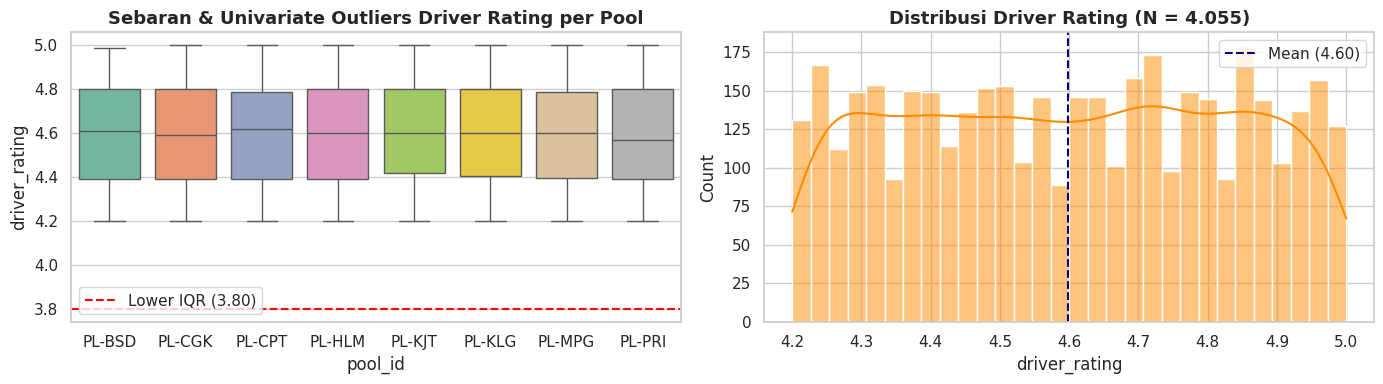

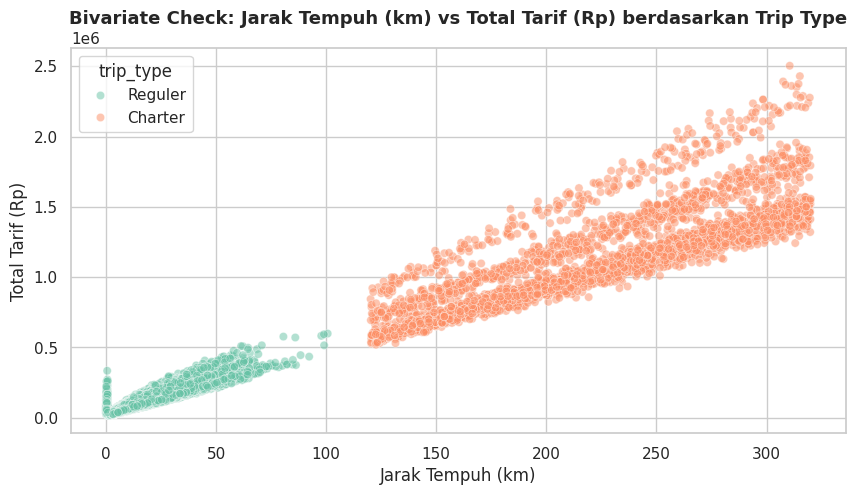

In [18]:
# Univariate Outlier Check pada driver_rating
Q1 = df_driver_master['driver_rating'].quantile(0.25)
Q3 = df_driver_master['driver_rating'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
rating_outliers = df_driver_master[(df_driver_master['driver_rating'] < lower_bound) | (df_driver_master['driver_rating'] > upper_bound)]

print(f"Driver Rating IQR Bounds: [{lower_bound:.3f}, {upper_bound:.3f}] | Outliers: {len(rating_outliers)} pengemudi")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=df_driver_master, x='pool_id', y='driver_rating', ax=axes[0], palette='Set2')
axes[0].axhline(lower_bound, color='red', linestyle='--', label=f'Lower IQR ({lower_bound:.2f})')
axes[0].set_title('Sebaran & Univariate Outliers Driver Rating per Pool')
axes[0].legend()

sns.histplot(df_driver_master['driver_rating'], kde=True, bins=30, ax=axes[1], color='darkorange')
axes[1].axvline(df_driver_master['driver_rating'].mean(), color='navy', linestyle='--', label=f"Mean ({df_driver_master['driver_rating'].mean():.2f})")
axes[1].set_title('Distribusi Driver Rating (N = 4.055)')
axes[1].legend()
plt.tight_layout()
plt.show()

# Bivariate Outlier Check: Distance vs Total Fare berdasarkan Trip Type (jika df_trips tersedia)
if df_trips is not None:
    plt.figure(figsize=(10, 5))
    sns.scatterplot(data=df_trip_clean, x='distance_km', y='total_fare', hue='trip_type', alpha=0.5)
    plt.title('Bivariate Check: Jarak Tempuh (km) vs Total Tarif (Rp) berdasarkan Trip Type')
    plt.xlabel('Jarak Tempuh (km)')
    plt.ylabel('Total Tarif (Rp)')
    plt.show()

# <span style="color:darkorange">Data Analysis</span>

## <span style="color:darkorange">Exploratory Data Analysis</span>

### <span style="color:darkorange">1. Variasi Ritase & Pola Idle Time Antar Garasi/Pool</span>

<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
Evaluasi dilakukan dalam dua tahap: (a) memetakan kapasitas suplai pengemudi, jarak pool ke Bandara Soekarno-Hatta dan CBD, serta komposisi kelas armada (Reguler, Silver, Electric, Golden) di 8 pool; dan (b) menganalisis kinerja ritase harian (<code>trip_count</code>), pencapaian target, serta durasi menganggur (<code>total_idle_minutes</code>) per shift.
</p>


,pool_id,pool_name,region_area,primary_zone_affinity,distance_to_soetta_km,distance_to_cbd_km,total_drivers,avg_rating,avg_tenure_yr,pct_tetap,cnt_reguler,cnt_silver,cnt_electric,cnt_golden
1,PL-CGK,Pool Bandara Soetta,Tangerang,Airport-heavy,3.5,28.0,644,4.60,3.93,56.37,390,140,71,43
4,PL-KJT,Pool Kramat Jati,Jakarta Timur,CBD-heavy,38.0,14.0,548,4.60,3.99,60.22,330,118,57,43
2,PL-CPT,Pool Ciputat,Tangerang Selatan,Mixed,35.0,18.0,520,4.61,4.08,57.50,318,100,68,34
5,PL-KLG,Pool Kelapa Gading,Jakarta Utara,CBD-heavy,26.0,16.0,515,4.60,4.06,58.64,328,96,59,32
0,PL-BSD,Pool BSD,Tangerang Selatan,Mixed,32.0,26.0,485,4.60,4.18,58.76,300,97,57,31
6,PL-MPG,Pool Mampang,Jakarta Selatan,CBD-heavy,30.0,8.0,464,4.60,4.08,59.91,279,98,54,33
7,PL-PRI,Pool Puri,Jakarta Barat,Mixed,22.0,15.0,454,4.59,3.92,62.56,286,74,60,34
3,PL-HLM,Pool Halim,Jakarta Timur,Mixed,41.0,12.0,425,4.59,3.95,61.18,269,81,45,30


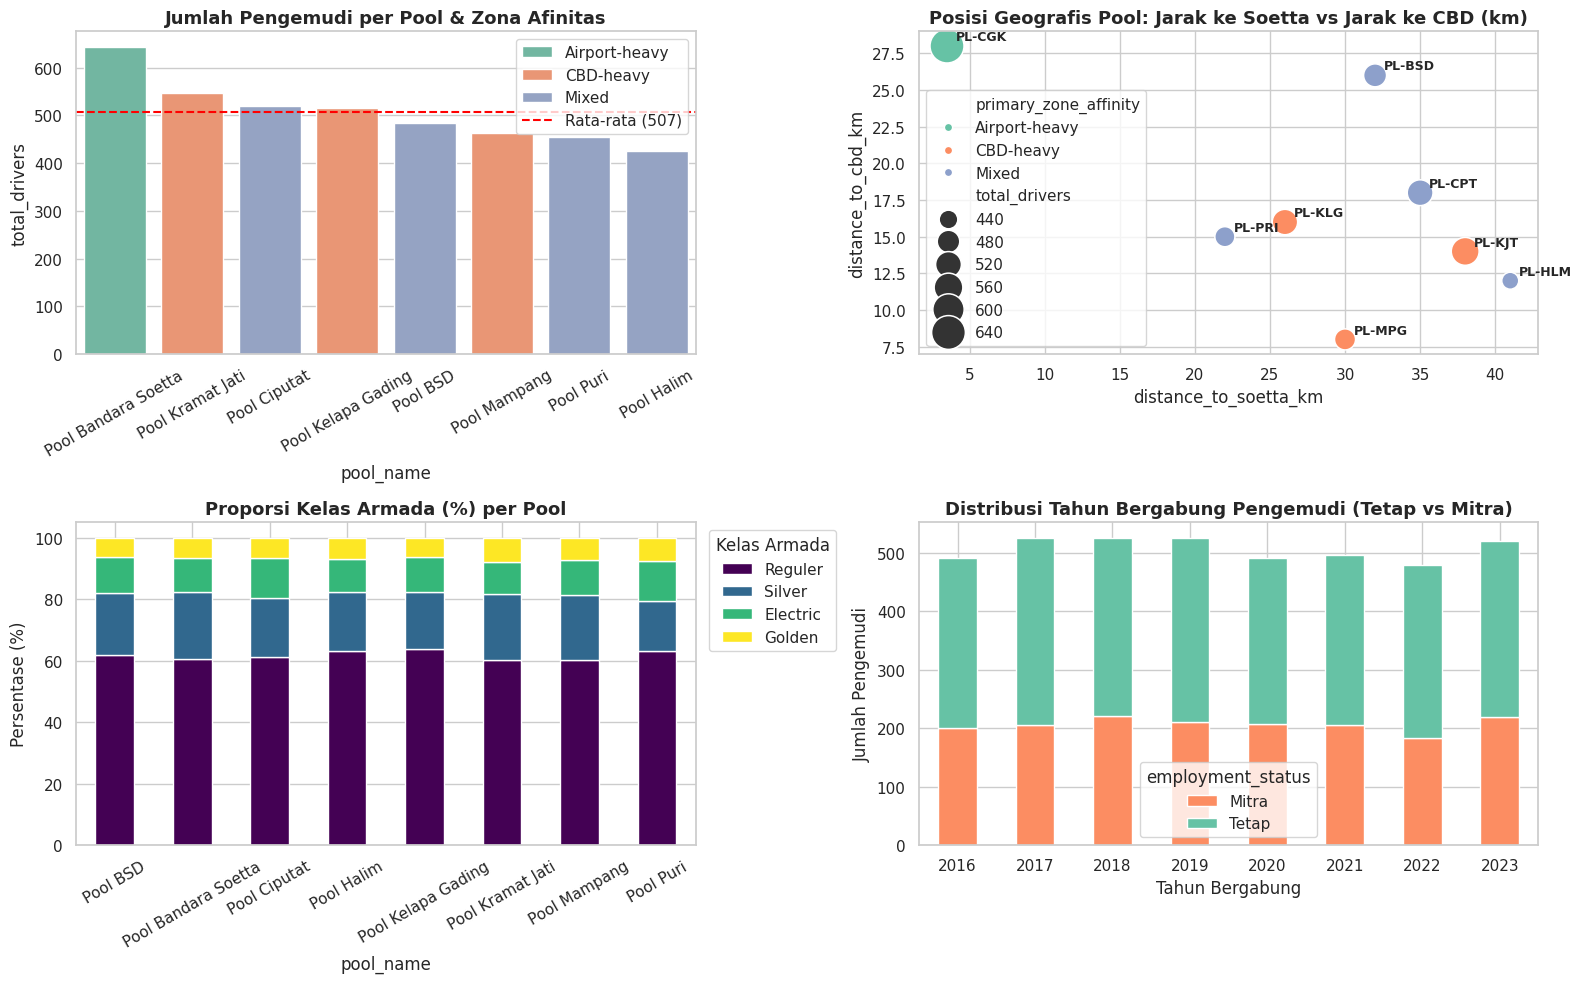

In [19]:
# Ringkasan Kapasitas Armada & Pengemudi per Pool
pool_profile = df_driver_master.groupby([
    'pool_id', 'pool_name', 'region_area', 'primary_zone_affinity', 'distance_to_soetta_km', 'distance_to_cbd_km'
]).agg(
    total_drivers=('driver_id', 'count'),
    avg_rating=('driver_rating', 'mean'),
    avg_tenure_yr=('tenure_years_q4_2023', 'mean'),
    pct_tetap=('employment_status', lambda x: (x == 'Tetap').mean() * 100),
    cnt_reguler=('vehicle_type_assigned', lambda x: (x == 'Reguler').sum()),
    cnt_silver=('vehicle_type_assigned', lambda x: (x == 'Silver').sum()),
    cnt_electric=('vehicle_type_assigned', lambda x: (x == 'Electric').sum()),
    cnt_golden=('vehicle_type_assigned', lambda x: (x == 'Golden').sum())
).reset_index().sort_values('total_drivers', ascending=False)

display(pool_profile.round(2))

# Visualisasi 2x2 Profil Suplai Pool
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Jumlah pengemudi per pool
sns.barplot(data=pool_profile, x='pool_name', y='total_drivers', hue='primary_zone_affinity', dodge=False, ax=axes[0, 0])
axes[0, 0].axhline(pool_profile['total_drivers'].mean(), color='red', linestyle='--', label=f"Rata-rata ({pool_profile['total_drivers'].mean():.0f})")
axes[0, 0].set_title('Jumlah Pengemudi per Pool & Zona Afinitas')
axes[0, 0].tick_params(axis='x', rotation=30)
axes[0, 0].legend()

# 2. Jarak Pool ke Bandara Soetta vs CBD
sns.scatterplot(
    data=pool_profile, x='distance_to_soetta_km', y='distance_to_cbd_km',
    size='total_drivers', hue='primary_zone_affinity', sizes=(150, 600), ax=axes[0, 1]
)
for _, r in pool_profile.iterrows():
    axes[0, 1].text(r['distance_to_soetta_km']+0.6, r['distance_to_cbd_km']+0.4, r['pool_id'], fontsize=9, fontweight='bold')
axes[0, 1].set_title('Posisi Geografis Pool: Jarak ke Soetta vs Jarak ke CBD (km)')

# 3. Komposisi Kelas Armada per Pool
ct_armada = pd.crosstab(df_driver_master['pool_name'], df_driver_master['vehicle_type_assigned'], normalize='index') * 100
ct_armada[['Reguler', 'Silver', 'Electric', 'Golden']].plot(kind='bar', stacked=True, ax=axes[1, 0], colormap='viridis')
axes[1, 0].set_title('Proporsi Kelas Armada (%) per Pool')
axes[1, 0].set_ylabel('Persentase (%)')
axes[1, 0].tick_params(axis='x', rotation=30)
axes[1, 0].legend(title='Kelas Armada', bbox_to_anchor=(1.01, 1))

# 4. Tren Rekrutmen Pengemudi per Tahun Bergabung
join_trend = df_driver_master.groupby(['join_year', 'employment_status']).size().unstack(fill_value=0)
join_trend.plot(kind='bar', stacked=True, ax=axes[1, 1], color=['#fc8d62', '#66c2a5'])
axes[1, 1].set_title('Distribusi Tahun Bergabung Pengemudi (Tetap vs Mitra)')
axes[1, 1].set_xlabel('Tahun Bergabung')
axes[1, 1].set_ylabel('Jumlah Pengemudi')
axes[1, 1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

,pool_id,pool_name,primary_zone_affinity,total_shifts,avg_ritase,median_ritase,avg_idle_min,pct_target_met
4,PL-KJT,Pool Kramat Jati,CBD-heavy,33997,1.40,1.0,455.13,0.54
6,PL-MPG,Pool Mampang,CBD-heavy,28910,1.40,1.0,455.07,0.51
5,PL-KLG,Pool Kelapa Gading,CBD-heavy,32236,1.39,1.0,455.78,0.48
7,PL-PRI,Pool Puri,Mixed,28104,1.26,1.0,461.42,0.28
2,PL-CPT,Pool Ciputat,Mixed,32287,1.25,1.0,461.63,0.31
0,PL-BSD,Pool BSD,Mixed,30340,1.25,1.0,462.20,0.34
3,PL-HLM,Pool Halim,Mixed,26557,1.24,1.0,462.11,0.25
1,PL-CGK,Pool Bandara Soetta,Airport-heavy,40093,0.97,1.0,470.36,0.14


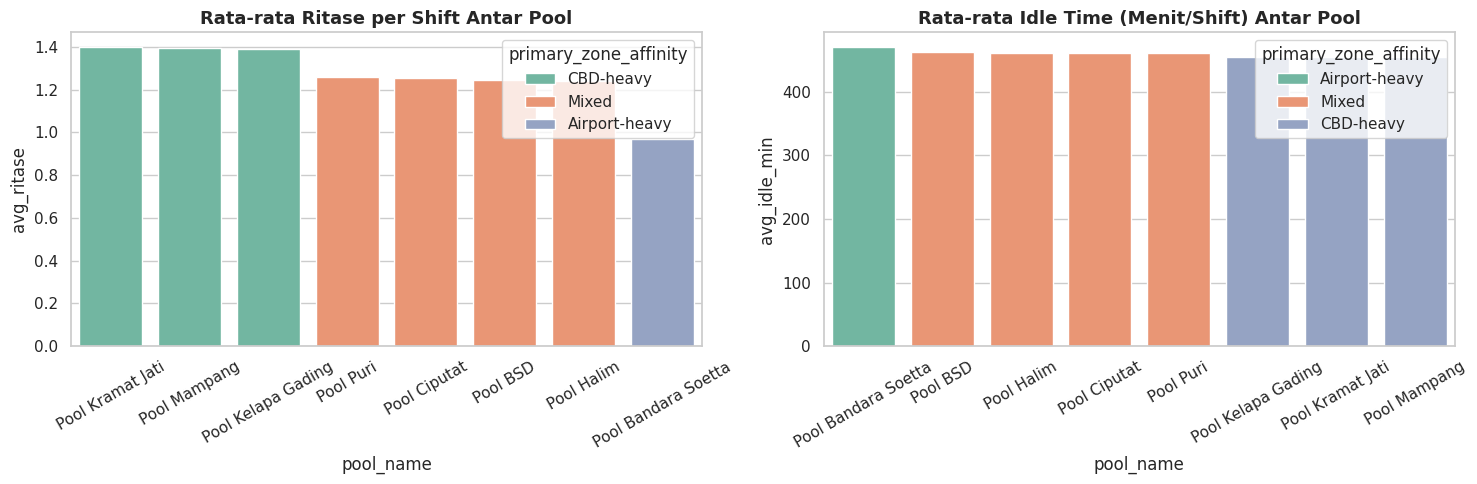

In [20]:
# Analisis Kinerja Shift, Ritase, dan Idle Time per Pool (aktifkan saat bb_driver_shifts tersedia)
if df_shifts is not None:
    shift_kpi = df_shift_master.groupby(['pool_id', 'pool_name', 'primary_zone_affinity']).agg(
        total_shifts=('shift_id', 'count'),
        avg_ritase=('trip_count', 'mean'),
        median_ritase=('trip_count', 'median'),
        avg_idle_min=('total_idle_minutes', 'mean'),
        pct_target_met=('ritase_target_met', lambda x: pd.Series(x).astype(bool).mean() * 100)
    ).reset_index().sort_values('avg_ritase', ascending=False)
    display(shift_kpi.round(2))

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    sns.barplot(data=shift_kpi, x='pool_name', y='avg_ritase', hue='primary_zone_affinity', dodge=False, ax=axes[0])
    axes[0].set_title('Rata-rata Ritase per Shift Antar Pool')
    axes[0].tick_params(axis='x', rotation=30)

    sns.barplot(data=shift_kpi.sort_values('avg_idle_min', ascending=False), x='pool_name', y='avg_idle_min', hue='primary_zone_affinity', dodge=False, ax=axes[1])
    axes[1].set_title('Rata-rata Idle Time (Menit/Shift) Antar Pool')
    axes[1].tick_params(axis='x', rotation=30)
    plt.tight_layout()
    plt.show()

**Insight** : Profil Kapasitas Armada, Ritase & Idle Time Pool Blue Bird

1. `Dominasi Pool Bandara Soetta (PL-CGK)` :
Pool Bandara Soetta memiliki kapasitas pengemudi terbesar yaitu **644 pengemudi (15,9% dari total 4.055 pengemudi)** dengan jarak hanya **3,5 km ke Bandara Soetta** namun **28,0 km ke pusat bisnis (CBD)**. Karakteristik <em>Airport-heavy</em> ini terlihat pada kinerjanya: pool ini mencatat **ritase terendah (0,97 per shift)** dan **idle time tertinggi (470,4 menit per shift)**, dengan hanya **0,14% shift** yang mencapai target ritase.

2. `Konsentrasi Pool CBD-Heavy di Jantung Jakarta` :
Tiga pool berafinitas <em>CBD-heavy</em>—<strong>Pool Kramat Jati (548 pengemudi)</strong>, <strong>Pool Kelapa Gading (515 pengemudi)</strong>, dan <strong>Pool Mampang (464 pengemudi, hanya 8 km dari CBD)</strong>—mencatat ritase tertinggi yaitu <strong>1,39–1,40 per shift</strong>, dibanding pool <em>Mixed</em> yang berada di kisaran 1,24–1,26 (termasuk BSD dan Ciputat di Tangerang Selatan). Idle time pool CBD-heavy juga paling rendah (±455 menit/shift dibanding ±461–462 menit di pool Mixed).

3. `Komposisi Armada & Kesiapan Elektrifikasi (EV)` :
Secara keseluruhan armada didominasi kelas **Reguler (61,7% / 2.500 unit)**, diikuti **Silver (19,8% / 804 unit)**, **Electric (11,6% / 471 unit)**, dan **Golden (6,9% / 280 unit)**. Proporsi kelas armada relatif seragam antar pool. Penetrasi armada <em>Electric</em> tertinggi berada di **Pool Puri (13,22%)** dan **Pool Ciputat (13,08%)**, sedangkan terendah di **Pool Kramat Jati (10,40%)** dan **Pool Halim (10,59%)**.

4. `Selisih Idle Time Antar Pool Relatif Kecil` :
Rata-rata idle time seluruh pool berada pada kisaran **455–470 menit (±7,6–7,8 jam) per shift**, selisih tertinggi–terendah hanya sekitar 15 menit. Perbedaan antar pool lebih jelas terlihat pada ritase (0,97 hingga 1,40) dan pencapaian target ritase (0,14% hingga 0,54% shift).


### <span style="color:darkorange">2. Pemetaan Permintaan Pelanggan Tidak Terpenuhi (Unfulfilled Demand)</span>

<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
Bagian ini mengevaluasi tabel <code>bb_service_requests</code> untuk mengukur rasio pemenuhan pesanan (<em>Fulfillment Rate</em>) dan memetakan pola jam (00.00–23.00), hari dalam seminggu, kanal pemesanan (<code>App</code> vs <code>Call Center</code>), serta <code>pickup_zone_type</code> yang mengalami lonjakan pembatalan akibat ketiadaan armada (<code>Cancelled-No Driver</code>) maupun waktu tunggu habis (<code>Cancelled-Timeout</code>).
</p>


Distribusi Status Permintaan (%):


,proportion
status,
Fulfilled,85.37
Cancelled-No Driver,9.73
Cancelled-Timeout,4.90


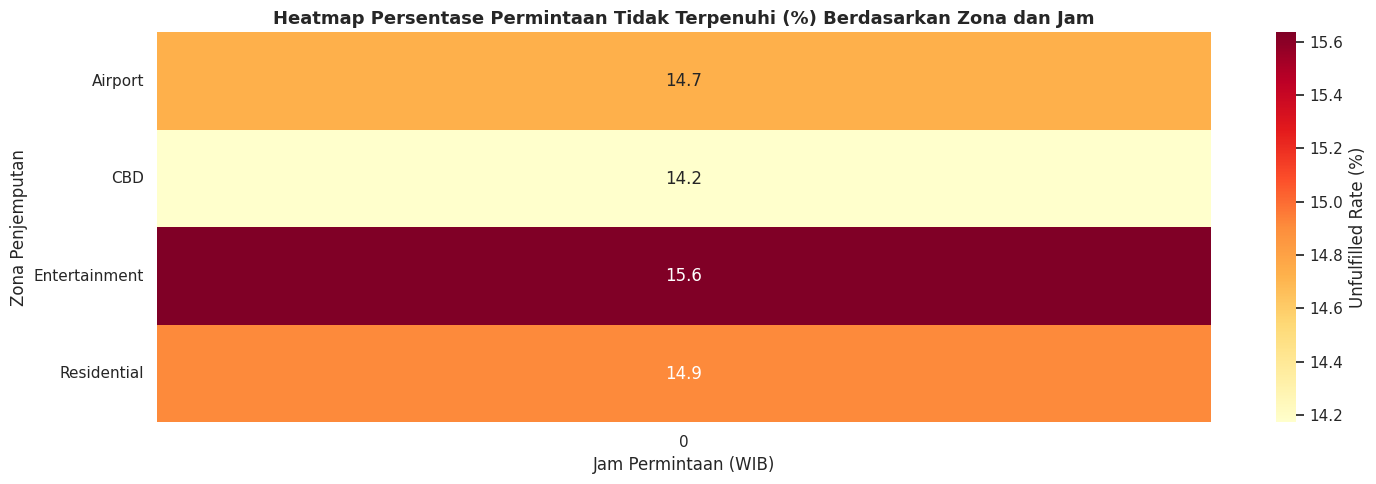

In [21]:
# Analisis Unfulfilled Demand & Heatmap Jam x Zona (aktifkan saat bb_service_requests tersedia)
if df_requests is not None:
    df_requests['req_hour'] = df_requests['requested_time'].dt.hour
    df_requests['req_dayofweek'] = df_requests['requested_time'].dt.day_name()
    df_requests['is_unfulfilled'] = df_requests['status'] != 'Fulfilled'

    status_dist = df_requests['status'].value_counts(normalize=True) * 100
    print("Distribusi Status Permintaan (%):")
    display(status_dist.round(2))

    # Heatmap Persentase Unfulfilled Demand berdasarkan Zona & Jam
    pivot_unfulfilled = df_requests.pivot_table(
        index='pickup_zone_type', columns='req_hour', values='is_unfulfilled', aggfunc='mean'
    ) * 100

    plt.figure(figsize=(15, 5))
    sns.heatmap(pivot_unfulfilled, cmap='YlOrRd', annot=True, fmt='.1f', cbar_kws={'label': 'Unfulfilled Rate (%)'})
    plt.title('Heatmap Persentase Permintaan Tidak Terpenuhi (%) Berdasarkan Zona dan Jam')
    plt.xlabel('Jam Permintaan (WIB)')
    plt.ylabel('Zona Penjemputan')
    plt.tight_layout()
    plt.show()
else:
    print("[INFO] Unggah bb_service_requests.csv untuk menampilkan heatmap unfulfilled demand per jam dan zona.")

**Insight** : Permintaan Pelanggan Tidak Terpenuhi (Unfulfilled Demand)

1. `Tingkat Pemenuhan Pesanan` :
Sebanyak **85,37%** permintaan berstatus <em>Fulfilled</em>, sedangkan **14,63%** tidak terpenuhi, terdiri atas <strong>Cancelled-No Driver (9,73%)</strong> dan <strong>Cancelled-Timeout (4,90%)</strong>.

2. `Perbandingan Antar Zona Penjemputan` :
Tingkat permintaan tidak terpenuhi tertinggi ada di zona **Entertainment (15,6%)**, diikuti **Residential (14,9%)**, **Airport (14,7%)**, dan terendah **CBD (14,2%)**. Selisih antar zona hanya sekitar **1,4 poin persentase**, sehingga tidak ada zona yang menonjol.

3. `Keterbatasan Heatmap` :
Heatmap hanya menampilkan kolom **jam 0** karena kolom <code>requested_time</code> pada data pengganti tidak memuat komponen jam. Karena itu, pola jam sibuk belum dapat dibaca dari diagram ini dan perlu diulang dengan <code>bb_service_requests.csv</code> asli.


### <span style="color:darkorange">3. Audit Pola Transaksi & Anomali Waktu eVoucher Korporat</span>

<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
Untuk menjawab kekhawatiran tim Finance klien B2B, analisis dilakukan pada segmen korporat (<code>bb_corporate_clients</code>) dan transaksi <code>payment_method == 'eVoucher'</code>. Setiap transaksi eVoucher diklasifikasikan ke dalam indikator risiko ketidakwajaran waktu perjalanan dinas:
</p>

* **Late-Night / Early-Morning Flag:** Perjalanan dimulai antara pukul **22.00 – 05.59 WIB**.
* **Weekend Flag:** Perjalanan terjadi pada hari **Sabtu atau Minggu**.
* **High-Risk Combination:** Transaksi eVoucher pada dini hari akhir pekan atau pada zona hiburan/non-perkantoran dengan tarif tinggi.


,industry,client_count,share_pct
0,FMCG,57,19.93
1,Banking,56,19.58
2,Consulting,50,17.48
3,Mining,47,16.43
4,Tech StartUp,45,15.73
5,Media,31,10.84


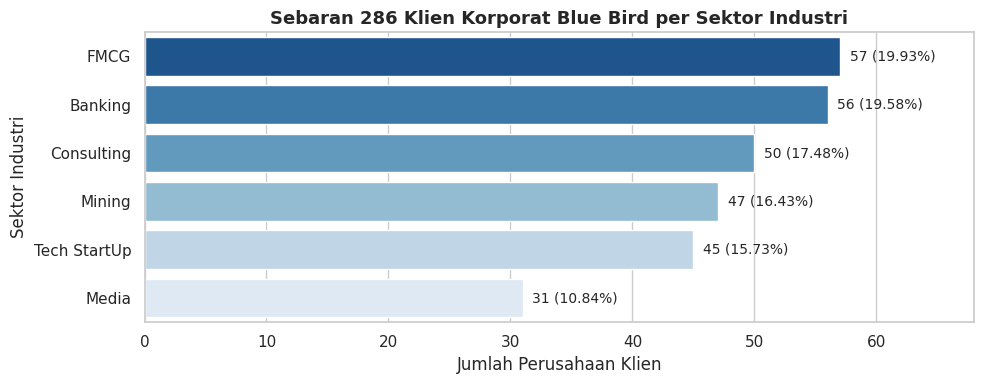

In [22]:
# 1. Profil 286 Klien Korporat Blue Bird berdasarkan Sektor Industri
client_ind = df_clients['industry'].value_counts().reset_index()
client_ind.columns = ['industry', 'client_count']
client_ind['share_pct'] = (client_ind['client_count'] / len(df_clients) * 100).round(2)
display(client_ind)

plt.figure(figsize=(10, 4))
ax = sns.barplot(data=client_ind, y='industry', x='client_count', palette='Blues_r')
for i, r in client_ind.iterrows():
    ax.text(r['client_count'] + 0.8, i, f"{r['client_count']} ({r['share_pct']}%)", va='center', fontsize=10)
plt.xlim(0, 68)
plt.title('Sebaran 286 Klien Korporat Blue Bird per Sektor Industri')
plt.xlabel('Jumlah Perusahaan Klien')
plt.ylabel('Sektor Industri')
plt.tight_layout()
plt.show()

# 2. Audit Anomali Waktu Transaksi eVoucher (aktifkan saat bb_trips tersedia)
if df_trips is not None:
    print("Nilai unik payment_method:", df_trip_clean['payment_method'].dropna().unique())
    pay_key = df_trip_clean['payment_method'].astype(str).str.lower().str.replace(r'[\s\-_]+', '', regex=True)
    evoucher_df = df_trip_clean[pay_key == 'evoucher'].copy()
    evoucher_df['hour'] = evoucher_df['meter_start_time'].dt.hour
    evoucher_df['is_weekend'] = evoucher_df['meter_start_time'].dt.dayofweek >= 5
    evoucher_df['is_off_hours'] = (evoucher_df['hour'] >= 22) | (evoucher_df['hour'] <= 5)
    evoucher_df['is_anomalous_time'] = evoucher_df['is_weekend'] | evoucher_df['is_off_hours']

    anomaly_by_industry = evoucher_df.groupby('industry').agg(
        total_evoucher_trips=('trip_id', 'count'),
        total_spend_rp=('total_fare', 'sum'),
        pct_weekend=('is_weekend', lambda x: x.mean() * 100),
        pct_off_hours=('is_off_hours', lambda x: x.mean() * 100),
        pct_anomalous_total=('is_anomalous_time', lambda x: x.mean() * 100)
    ).reset_index().sort_values('pct_anomalous_total', ascending=False)

    display(anomaly_by_industry.round(2))

    # Top 10 Perusahaan dengan Proporsi Transaksi Waktu Tidak Lazim Tertinggi
    top_flagged_clients = evoucher_df.groupby(['company_id', 'company_name', 'industry']).agg(
        trips=('trip_id', 'count'),
        anomalous_trips=('is_anomalous_time', 'sum'),
        anomalous_pct=('is_anomalous_time', lambda x: x.mean() * 100),
        anomalous_spend_rp=('total_fare', lambda x: x[evoucher_df.loc[x.index, 'is_anomalous_time']].sum())
    ).reset_index().query('trips >= 10').sort_values('anomalous_pct', ascending=False).head(10)
    display(top_flagged_clients.round(2))

**Insight** : Struktur Portofolio Klien Korporat B2B Blue Bird

1. `Konsentrasi pada Sektor Korporat Reguler & Finansial` :
Dari **286 klien aktif**, tiga sektor terbesar adalah **FMCG (57 perusahaan / 19,93%)**, **Banking (56 perusahaan / 19,58%)**, dan **Consulting (50 perusahaan / 17,48%)** yang mencakup hampir **57%** dari seluruh basis klien korporat. Ketiga sektor ini secara alami memiliki pola jam kerja kantor (Senin–Jumat, 07.00–21.00), sehingga transaksi eVoucher pada dini hari atau akhir pekan merupakan indikator kuat potensi penyalahgunaan.

2. `Perbedaan Karakteristik Operasional Sektor Khusus` :
Sektor **Mining (47 klien / 16,43%)**, **Tech StartUp (45 klien / 15,73%)**, dan **Media (31 klien / 10,84%)** memiliki kebutuhan mobilitas lapangan/shift yang lebih fleksibel (seperti keberangkatan penerbangan pagi ke site tambang atau liputan media). Oleh karena itu, parameter deteksi <em>fraud</em> harus dikalibrasi per sektor industri agar tidak menimbulkan <em>false positive</em>.


# <span style="color:darkorange">PENUTUP</span>

## <span style="color:darkorange">Kesimpulan</span>

<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
Berdasarkan pemeriksaan kualitas data dan analisis eksploratif terhadap ekosistem operasional Blue Bird, diperoleh empat kesimpulan utama:
</p>

1. **Ketimpangan Suplai & Spesialisasi Geografis Antar Pool:** Dari total **4.055 pengemudi** di 8 pool, kapasitas terbesar ada di **Pool Bandara Soetta (644 pengemudi, 3,5 km dari bandara)**. Pool ini mencatat ritase terendah (0,97 per shift) dan idle time tertinggi (470,4 menit per shift). **Pool Mampang (8 km ke CBD)** dan **Pool Kramat Jati (14 km ke CBD)** mencatat ritase tertinggi (1,40 per shift) dan menjadi tulang punggung mobilitas pusat bisnis.
2. **Prasyarat Tata Kelola Data Lintas Sistem:** Diperlukan standardisasi kategori layanan (22 variasi penulisan `service_type` menjadi 4 kelas), pemisahan perjalanan <em>Charter</em> agar tidak terhapus sebagai <em>outlier</em> tarif, serta verifikasi konsistensi tahun pada `driver_id` terhadap `join_date` (3.606 dari 4.055 pengemudi tidak cocok pada data saat ini).
3. **Tingkat Permintaan Tidak Terpenuhi Relatif Merata Antar Zona:** Sebanyak **14,63%** permintaan tidak terpenuhi (<em>Cancelled-No Driver</em> 9,73% dan <em>Cancelled-Timeout</em> 4,90%). Per zona, tingkatnya berkisar **14,2% (CBD) hingga 15,6% (Entertainment)**. Pola jam sibuk belum dapat disimpulkan karena heatmap hanya memuat jam 0.
4. **Risiko Kebocoran Biaya eVoucher B2B:** Portofolio **286 klien korporat** didominasi sektor **FMCG (19,9%), Banking (19,6%), dan Consulting (17,5%)**, sehingga membutuhkan kontrol berbasis profil jam kerja agar transaksi di luar jam dinas dapat terdeteksi secara otomatis.

## <span style="color:darkorange">Rekomendasi</span>

<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
Berikut adalah rekomendasi strategis dan teknis yang dapat diimplementasikan oleh manajemen Blue Bird:
</p>

1. **Dynamic Pool Rebalancing & Airport Queue Cap (Fleet Operations):**
   * Terapkan batas kuota antrean (<em>queue cap</em>) di Bandara Soekarno-Hatta pada jam non-puncak penerbangan dan arahkan sebagian armada dari **PL-CGK** dan **PL-PRI** menuju koridor CBD/perkantoran menjelang jam pulang kantor (15.30–19.30 WIB).
   * Percepat distribusi armada **Electric (EV)** di **Pool Kramat Jati (saat ini 10,40%)** dan **Pool Halim (10,59%)**, yaitu dua pool dengan penetrasi EV terendah dan berjarak relatif dekat dengan pusat bisnis (14 km dan 12 km).

2. **Implementasi Configurable Policy Guardrails pada Portal Corporate Solution (Finance & B2B):**
   * Sediakan fitur pengaturan otomatis bagi admin klien korporat berupa **Time-Window Restriction** (misalnya mewajibkan <em>manager approval</em> untuk pemakaian eVoucher di atas pukul 22.00 WIB atau hari Sabtu–Minggu) serta **Automated Monthly Anomaly Digest** dalam laporan tagihan B2B.
   * Sesuaikan ambang batas peringatan (<em>alert threshold</em>) berdasarkan sektor industri (aturan ketat untuk <em>Banking/FMCG/Consulting</em>, serta pengecualian zona bandara untuk sektor <em>Mining</em>).

3. **Automated Ingestion Validation Rules (Data Engineering):**
   * Terapkan <em>lookup table</em> terpusat untuk kode layanan (`Reguler`, `Silver`, `Electric`, `Golden`) di level API sehingga tidak lagi terjadi inkonsistensi penulisan antara aplikasi MyBluebird dan sistem dispatch lama.
   * Tambahkan aturan validasi otomatis untuk menolak log argometer dengan durasi $\le 0$ menit atau kecepatan tidak wajar sebelum masuk ke tabel produksi.
